### Evaluation

Notebook to run evaulation on test data

- use daily provided data (evaluation period of competition)

Data: "../data/evaluation/[met_nowcast_daily, met_forecast_daily, wind_power]"


In [6]:
import os
import sys

sys.path.append("../src")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from jax import random
from numpyro.infer import Predictive
import arviz as az

from validate_example import validate_forecast
from data_processing.load import (
    load_evaluation_data,
    load_weather_forecast_parquet,
    load_and_preprocess_forecast_data,
    rename_met_forecast_columns,
    sin_cos_transform,
    load_weather_nowcast,
    load_evaluation_forecast_data,
)
from data_processing.utils import (
    load_scaler_params,
    load_checkpoint,
    load_torch_model,
    save_scaler_params,
    QuantileDistribution,
)
from models.model import model_mw_gamma, model_cf_logitnormal, model_cf_beta
from training.evaluate import test_QR, test_BNN
import torch
import re

from configs.load_config import load_config

### Load evaluation data


In [ ]:
model_cfg = load_config("../configs/model/torch_model_quantile.yaml")
file_name = "WindPowerQuantile_2025-12-21_10-21-23_forecast_gen_ELSPOT_NO1"
data_cfg = load_config(model_cfg.data.path)

In [4]:
bid_zone = model_cfg.data.bid_zone
bid_zones = ["ELSPOT NO1", "ELSPOT NO2", "ELSPOT NO3", "ELSPOT NO4"]
bid_zones = [bz.replace(" ", "_") for bz in bid_zones]


dataset = data_cfg.dataset
if dataset == "nowcast":
    evaluation_dates = [
        "2025-09-22",
        "2025-09-23",
        "2025-09-24",
        "2025-09-25",
        "2025-09-26",
        "2025-09-29",
        "2025-09-30",
        # "2025-10-01",
        # "2025-10-02",
        # "2025-10-03",
    ]

    scaler_data_nowcast = load_scaler_params(
        bid_zone=bid_zone, dataset="nowcast", dir_path="../checkpoints"
    )

    eval_data = load_evaluation_data(
        dates=evaluation_dates,
        scaler_params=scaler_data_nowcast["scaler_params"],
        site_scaler_params=scaler_data_nowcast["site_scaler_params"],
        bid_zone=bid_zone,
    )

elif dataset == "forecast":
    evaluation_dates = [
        "2025-09-22",
        "2025-09-23",
        "2025-09-24",
        "2025-09-25",
        "2025-09-26",
        "2025-09-29",
        "2025-09-30",
        "2025-10-01",
        "2025-10-02",
        "2025-10-03",
    ]

    scaler_data_forecast = load_scaler_params(
        bid_zone=bid_zone, dataset="forecast", dir_path="../checkpoints"
    )

    eval_data = load_evaluation_forecast_data(
        dates=evaluation_dates,
        scaler_params=scaler_data_forecast["scaler_params"],
        site_scaler_params=scaler_data_forecast["site_scaler_params"],
        bid_zone=bid_zone,
        ensemble_members=None,
        variance_feature=True,
    )

Loaded scaler parameters for ELSPOT NO1 and forecast
  Saved at: 2025-12-21 11:20:57
  Split time: 2025-01-01 00:00:00+01:00
Loading evaluation data for 10 dates in zone ELSPOT NO1...
Loading evaluation data for 2025-09-22 in zone ELSPOT NO1
RangeIndex(start=0, stop=4087, step=1)
Dropping 15 gust columns not present in nowcast

Column mapping summary:
  Original columns: 94
  Renamed columns: 79
  Dropped columns: 15
  Final columns: 79

 RangeIndex(start=0, stop=4087, step=1)


/Users/noemiweber/Documents/Studium/master/4.semester_norway/WindAIcompetition/notebooks/../src/data_processing/downtime.py:63: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  maintenance_events.drop(


QUEUEING TASKS | Calculating available capacity across full time range:   0%|          | 0/56298 [00:00<?, ?it…

PROCESSING TASKS | Calculating available capacity across full time range:   0%|          | 0/56298 [00:00<?, ?…

COLLECTING RESULTS | Calculating available capacity across full time range:   0%|          | 0/56298 [00:00<?,…

/Users/noemiweber/Documents/Studium/master/4.semester_norway/WindAIcompetition/notebooks/../src/data_processing/downtime.py:63: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  maintenance_events.drop(


... (41 outputs left out)

QUEUEING TASKS | Calculating available capacity across full time range:   0%|          | 0/56298 [00:00<?, ?it…

PROCESSING TASKS | Calculating available capacity across full time range:   0%|          | 0/56298 [00:00<?, ?…

COLLECTING RESULTS | Calculating available capacity across full time range:   0%|          | 0/56298 [00:00<?,…

Preprocessing done. X_eval shape: (240, 6, 15, 11)


### Evaluate on test set


In [ ]:
if model_cef.backend == "numpyro":
    forecast, forecast_extended = test_BNN(file_name, eval_data)
elif model_cfg.backend == "torch":
    forecast, forecast_extended = test_QR(
        file_name, eval_data, ensembles=False, from_now_to_forecast=False
    )

In [ ]:
# # Save predictions to CSV
# data_folder = f"../data/evaluation/eval_period"
# file_path = f"{data_folder}/forecast.csv"
# if not os.path.exists(data_folder):
#     os.makedirs(data_folder)
# forecast.to_csv(file_path)

In [ ]:
# # Validate format
# df = validate_forecast(file_path)

### Metrics


In [13]:
i = 0  # [0,1,2,3], choose which bid zone should be plotted
bid_zone = f"ELSPOT_NO{i+1}"
rmse = np.sqrt(np.mean((forecast[bid_zone] - eval_data["Y_eval_gen"]) ** 2))

print("Test RMSE (gen prediction):", rmse)
inside = (eval_data["Y_eval_gen"] >= forecast_extended[i]["hdi_lower"]) & (
    eval_data["Y_eval_gen"] <= forecast_extended[i]["hdi_upper"]
)
coverage_90 = inside.mean()
print(f"\nEmpirical coverage (0.025–0.975): {coverage_90:.3f}")

below_median = (eval_data["Y_eval_gen"] <= forecast_extended[i]["median"]).mean()
print(f"Below median (should be ~0.5): {below_median:.3f}")

Test RMSE (gen prediction): 92.35111996897626

Empirical coverage (0.025–0.975): 0.658
Below median (should be ~0.5): 0.167


### Plot prediction


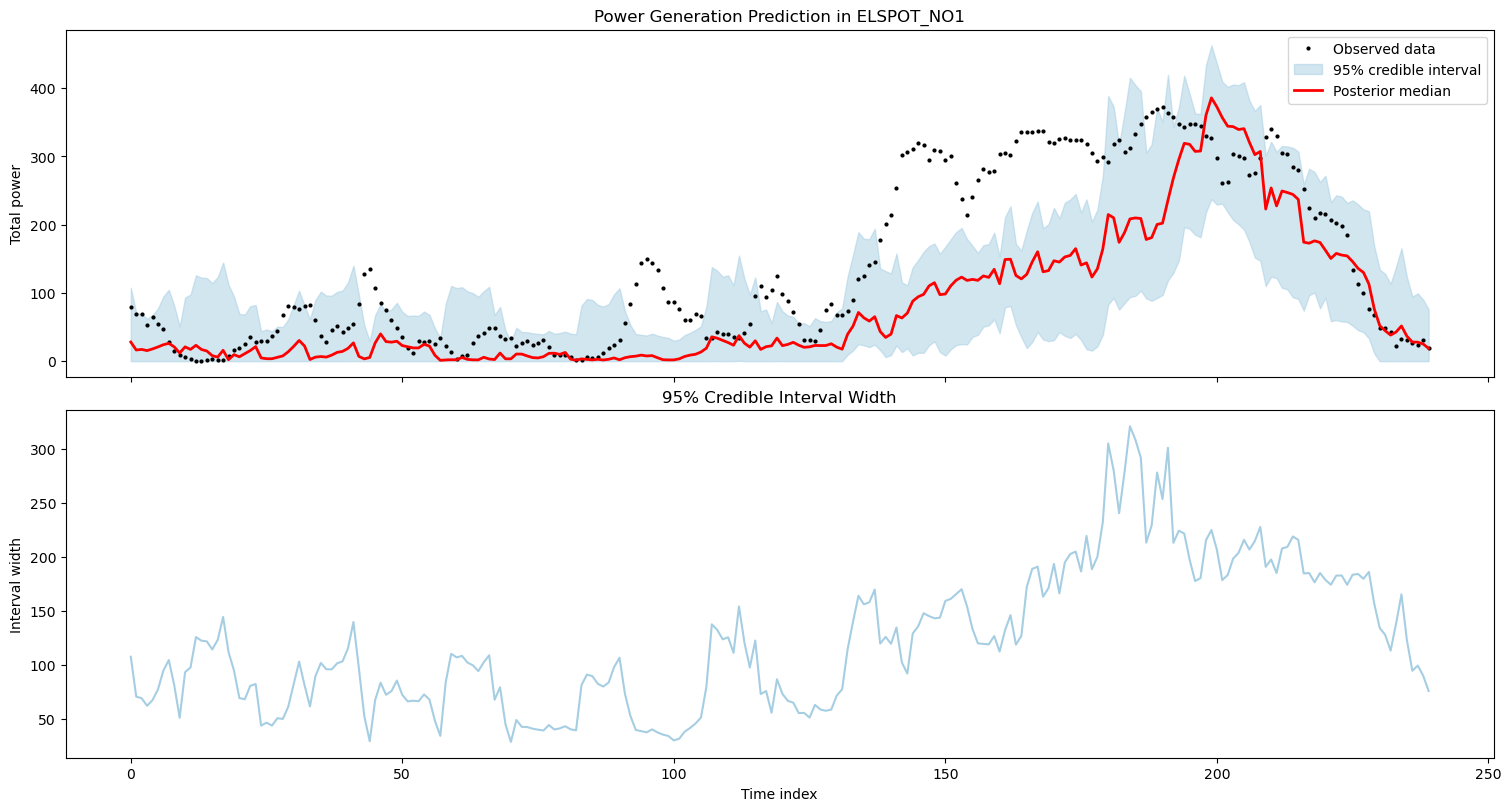

In [14]:
fig, axes = plt.subplots(nrows=2, figsize=(15, 8), sharex=True, constrained_layout=True)

ax = axes[0]
ax.plot(
    eval_data["Y_eval_gen"],
    ".",
    color="black",
    label="Observed data",
    markersize=4,
)

ax.fill_between(
    np.arange(
        len(forecast_extended[i].index)
    ),  # np.arange(24 * len(evaluation_dates)),
    forecast_extended[i]["hdi_lower"].values,
    forecast_extended[i]["hdi_upper"].values,
    color="#A6CEE3",
    alpha=0.5,
    label="95% credible interval",
)

ax.plot(
    forecast_extended[i]["median"].values, color="red", label="Posterior median", lw=2
)

ax.set(
    ylabel="Total power",
    title=f"Power Generation Prediction in {bid_zone}",
)
ax.legend()


# Compute interval width
width = (
    forecast_extended[i]["hdi_upper"].values - forecast_extended[i]["hdi_lower"].values
)
ax2 = axes[1]
ax2.plot(width, color="#A6CEE3")
ax2.set(
    xlabel="Time index",
    ylabel="Interval width",
    title="95% Credible Interval Width",
)

plt.show()

In [ ]:
# # First, load nowcast data (or load existing scaler params)
# nowcast_data = load_and_preprocess_data(bid_zone="ELSPOT NO1")

In [ ]:
# # Now load forecast data using the SAME scaler parameters

# forecast_data = load_and_preprocess_forecast_data(
#     scaler_params=None,
#     site_scaler_params=None,
#     bid_zone="ELSPOT NO1",
#     ensemble_member=0,  # Use member 0
#     data_path="../data",
# )

In [ ]:
# # Plot cf vs gen model for QR
# fig, axes = plt.subplots(nrows=2, figsize=(10, 7), sharex=True, constrained_layout=True)

# ax = axes[0]
# ax.plot(
#     eval_data["Y_eval_gen"],
#     ".",
#     color="black",
#     label="Observed data",
#     markersize=4,
# )

# # file_name = "WindPowerQuantile_2025-12-02_11-34-46_fore_ELSPOT_NO1"
# # file_name="WindPowerModel_simple_2025-12-02_11-11-30_fore_ELSPOT_NO1"
# # file_name = "WindPowerQuantile_2025-12-03_14-57-43_now_gen_ELSPOT_NO1"
# file_name = "WindPowerQuantile_2025-12-04_12-21-40_now_gen_ELSPOT_NO1"
# # file_name = "WindPowerQuantile_2025-12-03_14-54-34_now_cf_ELSPOT_NO1"
# # file_name = "WindPowerModel_simple_2025-12-01_10-31-55_ELSPOT_NO1"

# forecast, forecast_extended = evaluate_QR(file_name)

# ax.fill_between(
#     np.arange(24 * len(evaluation_dates)),
#     forecast_extended[i]["hdi_lower"].values,
#     forecast_extended[i]["hdi_upper"].values,
#     color="#A6CEE3",
#     alpha=0.5,
#     label="95% credible interval",
# )

# ax.plot(
#     forecast_extended[i]["median"].values, color="red", label="Posterior median", lw=2
# )

# ax.set(
#     ylabel="Total power",
#     title=f"QR Power Generation Prediction in {bid_zone}",
# )
# ax.legend(fontsize=14)
# ax.title.set_fontsize(18)
# ax.xaxis.label.set_size(16)
# ax.yaxis.label.set_size(16)


# ax = axes[1]
# ax.plot(
#     eval_data["Y_eval_gen"],
#     ".",
#     color="black",
#     label="Observed data",
#     markersize=4,
# )
# # file_name = "WindPowerQuantile_2025-12-02_11-34-46_fore_ELSPOT_NO1"
# # file_name="WindPowerModel_simple_2025-12-02_11-11-30_fore_ELSPOT_NO1"
# # file_name = "WindPowerQuantile_2025-12-03_14-57-43_now_gen_ELSPOT_NO1"
# file_name = "WindPowerQuantile_2025-12-03_14-54-34_now_cf_ELSPOT_NO1"
# # file_name = "WindPowerModel_simple_2025-12-01_10-31-55_ELSPOT_NO1"

# forecast, forecast_extended = evaluate_QR(file_name)

# ax.fill_between(
#     np.arange(24 * len(evaluation_dates)),
#     forecast_extended[i]["hdi_lower"].values,
#     forecast_extended[i]["hdi_upper"].values,
#     color="#A6CEE3",
#     alpha=0.5,
#     label="95% credible interval",
# )

# ax.plot(
#     forecast_extended[i]["median"].values, color="red", label="Posterior median", lw=2
# )

# ax.set(
#     xlabel="Time Index (Forecast test period)",
#     ylabel="Total power",
#     title=f"QR Capacity Factor Prediction in {bid_zone}",
# )
# ax.title.set_fontsize(18)
# ax.xaxis.label.set_size(16)
# ax.yaxis.label.set_size(16)

# plt.show()

In [ ]:
# # Plot cf vs gen model for BNN
# fig, axes = plt.subplots(nrows=2, figsize=(10, 7), sharex=True, constrained_layout=True)

# ax = axes[0]
# ax.plot(
#     eval_data["Y_eval_gen"],
#     ".",
#     color="black",
#     label="Observed data",
#     markersize=4,
# )

# file_name = "model_mw_gamma_2025-11-21_10-30-46_gen_ELSPOT_NO1"
# forecast, forecast_extended = evaluate_BNN(file_name)

# ax.fill_between(
#     np.arange(24 * len(evaluation_dates)),
#     forecast_extended[i]["hdi_lower"].values,
#     forecast_extended[i]["hdi_upper"].values,
#     color="#A6CEE3",
#     alpha=0.5,
#     label="95% credible interval",
# )

# ax.plot(
#     forecast_extended[i]["median"].values, color="red", label="Posterior median", lw=2
# )

# ax.set(
#     ylabel="Total power",
#     title=f"BNN Power Generation Prediction (Gamma) in {bid_zone}",
# )
# ax.legend(fontsize=14)
# ax.title.set_fontsize(18)
# ax.xaxis.label.set_size(16)
# ax.yaxis.label.set_size(16)


# ax = axes[1]
# ax.plot(
#     eval_data["Y_eval_gen"],
#     ".",
#     color="black",
#     label="Observed data",
#     markersize=4,
# )
# file_name = "model_cf_beta_2025-12-01_10-03-45_cf_ELSPOT_NO1"

# forecast, forecast_extended = evaluate_BNN(file_name)

# ax.fill_between(
#     np.arange(24 * len(evaluation_dates)),
#     forecast_extended[i]["hdi_lower"].values,
#     forecast_extended[i]["hdi_upper"].values,
#     color="#A6CEE3",
#     alpha=0.5,
#     label="95% credible interval",
# )

# ax.plot(
#     forecast_extended[i]["median"].values, color="red", label="Posterior median", lw=2
# )

# ax.set(
#     xlabel="Time Index (Forecast test period)",
#     ylabel="Total power",
#     title=f"BNN Capacity Factor Prediction (Beta) in {bid_zone}",
# )
# ax.title.set_fontsize(18)
# ax.xaxis.label.set_size(16)
# ax.yaxis.label.set_size(16)

# plt.show()